[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/fingerprint-similarity-guide/blob/main/notebooks/07_benchmark_knn_qsar.ipynb)

# 07 · Benchmark 4 — Nearest-Neighbour QSAR

*Fingerprint & Similarity Guide · Hamza Hentabli, Ph.D. · ~50 min*

If similar molecules have similar activity, then the simplest possible model is: *predict a new molecule's property from its nearest neighbours*. This **k-NN QSAR** is a pure test of a fingerprint+metric pairing — no learning algorithm to hide behind. We benchmark every combination with 5-fold cross-validation on the **ESOL** aqueous-solubility set (1,128 compounds, a neutral regression task) and report R² and RMSE.

**Learning objectives.** By the end of this notebook you will be able to:

- build a similarity-weighted k-NN regressor from fingerprints alone
- cross-validate it fairly and report R² / RMSE
- compare all fingerprints and metrics on a continuous endpoint
- see why **count** and **atom-pair** fingerprints win neighbour-based prediction here

In [1]:
# Setup: on Google Colab this installs dependencies and clones the repo so the
# cached data and the shared `fsg` helper module are available. Running locally,
# install requirements.txt once and this cell just locates the files.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("FSG_OFFLINE", "0") == "1"   # CI sets this; no notebook needs the network
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "rdkit", "scikit-learn", "scipy", "pandas", "matplotlib"], check=True)
    if not os.path.isdir("fingerprint-similarity-guide"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/fingerprint-similarity-guide.git"], check=True)
    ROOT = "fingerprint-similarity-guide"
else:
    ROOT = ".." if os.path.isdir("../data") else "."
DATA_DIR = os.path.join(ROOT, "data")
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
import fsg   # shared fingerprint factory + metrics + evaluation

print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| data:", DATA_DIR)
print("Fingerprints available:", ", ".join(fsg.FP_NAMES))

Colab: False | offline: True | data: ../data
Fingerprints available: ECFP4-1024, ECFP4-2048, ECFP6-2048, ECFP4-counts, FCFP4-2048, RDKit, AtomPair, Torsion, MACCS, Avalon


In [2]:
import numpy as np, pandas as pd
esol = fsg.load_mols(pd.read_csv(f"{DATA_DIR}/esol_delaney.csv"))
print(f"{len(esol)} compounds; endpoint = logS (aqueous solubility)")
print(esol[["logS"]].describe().round(2).T)

1128 compounds; endpoint = logS (aqueous solubility)
       count  mean  std   min   25%   50%  75%   max
logS  1128.0 -3.05  2.1 -11.6 -4.32 -2.86 -1.6  1.58


## 1. Similarity-weighted k-NN

To predict a test molecule's logS: find its **k most similar** training molecules and take a similarity-weighted average of *their* logS. Distance = 1 − similarity. No feature scaling, no hyperparameter tuning beyond k — so the score reflects the **fingerprint + metric**, nothing else.

## 2. The method, computed live (two fingerprints)

5-fold CV, k=5, Tanimoto — the exact protocol in `scripts/run_benchmarks.py`.

In [3]:
from sklearn.model_selection import KFold
yv = esol["logS"].to_numpy()
kf = KFold(n_splits=5, shuffle=True, random_state=42)
K = 5
def knn_cv(name, metric="tanimoto"):
    fps = fsg.make_fps(name, list(esol["mol"]))
    preds = np.zeros(len(yv))
    for tr, te in kf.split(fps):
        tr_fps = [fps[t] for t in tr]
        for ti in te:
            sims = np.array(fsg.bulk_similarity(metric, fps[ti], tr_fps))
            top = np.argsort(-sims)[:K]; w = sims[top]
            preds[ti] = yv[tr].mean() if w.sum() <= 0 else np.average(yv[tr][top], weights=w)
    r2 = 1 - np.sum((yv-preds)**2) / np.sum((yv-yv.mean())**2)
    rmse = float(np.sqrt(np.mean((yv-preds)**2)))
    return round(r2, 3), round(rmse, 3)
for name in ["ECFP4-counts", "MACCS"]:
    r2, rmse = knn_cv(name)
    print(f"{name:14s} R2={r2}  RMSE={rmse}")

ECFP4-counts   R2=0.772  RMSE=1.0


MACCS          R2=0.674  RMSE=1.197


## 3. Full fingerprint × metric grid

The committed results run this CV for every fingerprint × metric. Here is R² for all of them.

In [4]:
import json, os
import pandas as pd
DOCS_DIR = os.path.join(ROOT, "docs")
RESULTS = json.load(open(os.path.join(DOCS_DIR, "benchmark_results.json")))
print("Loaded committed benchmark results from docs/benchmark_results.json")

Loaded committed benchmark results from docs/benchmark_results.json


In [5]:
b4 = RESULTS["benchmark4_knn_qsar_esol"]["scores"]
metrics = ["tanimoto", "dice", "cosine", "tversky", "russel"]
knn_grid = pd.DataFrame(index=fsg.FP_NAMES, columns=metrics, dtype=float)
for key, v in b4.items():
    fp, mt = key.split("|"); knn_grid.loc[fp, mt] = v["R2"]
knn_grid.round(3)

,tanimoto,dice,cosine,tversky,russel
ECFP4-1024,0.642,0.635,0.620,0.561,0.380
ECFP4-2048,0.652,0.645,0.620,0.585,0.417
ECFP6-2048,0.674,0.668,0.642,0.598,0.395
ECFP4-counts,0.772,0.768,NaN,NaN,NaN
FCFP4-2048,0.691,0.685,0.668,0.632,0.425
RDKit,0.730,0.725,0.721,0.630,0.084
AtomPair,0.767,0.764,0.759,0.600,-0.172
Torsion,0.559,0.554,0.539,0.427,0.174
MACCS,0.674,0.669,0.652,0.548,0.225
Avalon,0.709,0.704,0.702,0.636,0.260


In [6]:
best = max(b4.items(), key=lambda kv: kv[1]["R2"])
print("Best k-NN QSAR combination on ESOL (R2):", best[0], "->", best[1])
# worst sensible combo for contrast
worst = min(b4.items(), key=lambda kv: kv[1]["R2"])
print("Worst combination (metric mismatch):", worst[0], "->", worst[1])

Best k-NN QSAR combination on ESOL (R2): ECFP4-counts|tanimoto -> {'R2': 0.772, 'RMSE': 1.0}
Worst combination (metric mismatch): AtomPair|russel -> {'R2': -0.172, 'RMSE': 2.268}


## 4. What wins and why

**Count fingerprints (ECFP4-counts) and atom pairs** give the best neighbour-based predictions on ESOL — solubility depends on *how many* of each polar/non-polar feature a molecule has, and count/atom-pair fingerprints preserve that multiplicity and connectivity. **Tanimoto and Dice** are the safe metric choices; **Russel-Rao is a disaster** for neighbour prediction (it can even give negative R², worse than predicting the mean), because it rewards overall bit-sparsity rather than genuine overlap.

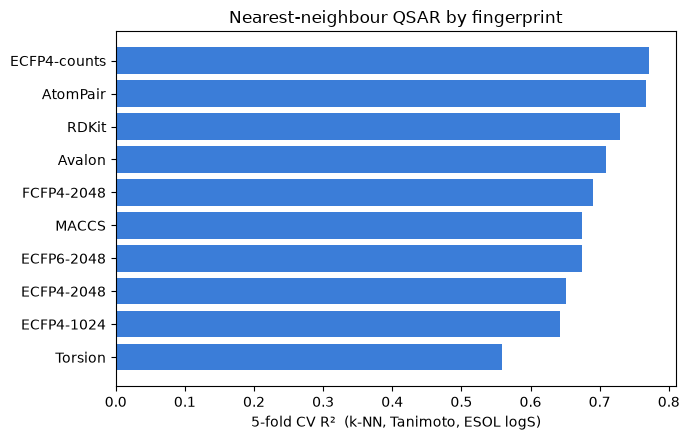

In [7]:
import matplotlib.pyplot as plt
tani = {n: b4[f"{n}|tanimoto"]["R2"] for n in fsg.FP_NAMES}
order = sorted(tani, key=tani.get)
plt.figure(figsize=(7,4.5))
plt.barh(order, [tani[n] for n in order], color="#3b7dd8")
plt.xlabel("5-fold CV R²  (k-NN, Tanimoto, ESOL logS)")
plt.title("Nearest-neighbour QSAR by fingerprint")
plt.tight_layout(); plt.show()

## Summary

- Pure **k-NN QSAR** isolates the fingerprint+metric quality — no model to mask it.
- On ESOL, **ECFP4-counts and AtomPair + Tanimoto/Dice** predict solubility best.
- **Russel-Rao (and often Tversky) ruin** neighbour prediction — the metric matters as much as the fingerprint.
- Counts beat binary here because solubility tracks *how many* polar groups there are.

Next: a focused look at the size/folding and count-vs-binary trade-offs we have been hinting at.

### ✏️ Exercise 1

Run `knn_cv` for AtomPair with Tanimoto vs Russel-Rao. How much does the bad metric cost?

<details>
<summary><b>Show solution</b></summary>

```python
print("AtomPair Tanimoto:", knn_cv("AtomPair","tanimoto"))
print("AtomPair Russel  :", knn_cv("AtomPair","russel"))
```

</details>

### ✏️ Exercise 2

From the grid, list the top 3 fingerprint+metric combinations by R².

<details>
<summary><b>Show solution</b></summary>

```python
top = sorted(b4.items(), key=lambda kv: -kv[1]["R2"])[:3]
for k,v in top: print(k, v["R2"])
```

</details>